In [1]:
import pandas as pd
import numpy as np
from sklearn.datasets import fetch_california_housing

import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline 

In [2]:
data = fetch_california_housing(as_frame=True)
df = data.frame

In [131]:
df.columns = df.columns.str.lower()

In [132]:
df.head()

,medinc,houseage,averooms,avebedrms,population,aveoccup,latitude,longitude,medhouseval
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


<Axes: xlabel='medhouseval', ylabel='Count'>

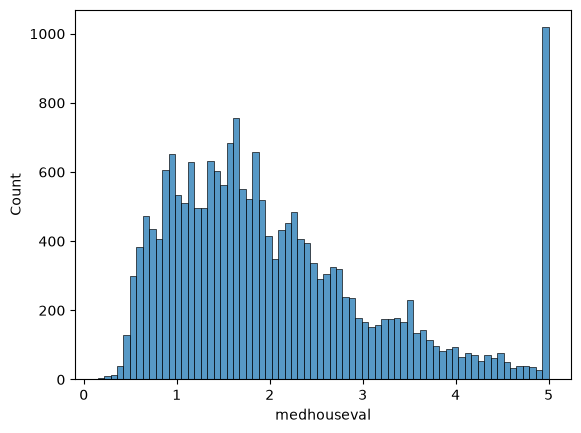

In [13]:
sns.histplot(df.medhouseval, bins=70)

<Axes: xlabel='medhouseval', ylabel='Count'>

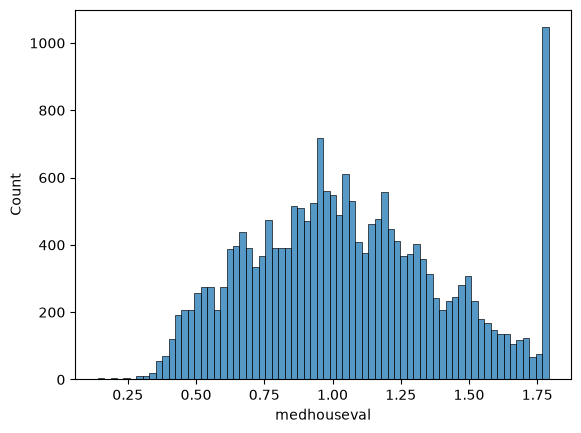

In [87]:
# no changes are applied here yet 
modVal = np.log1p(df.medhouseval)
sns.histplot(modVal, bins=70)

In [120]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

In [121]:
np.random.seed(1)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train+n_val]]
df_test = df.iloc[idx[n_train+n_val:]]

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [122]:
y_train = np.log1p(df_train['medhouseval'].values)
y_val = np.log1p(df_val['medhouseval'].values)
y_test = np.log1p(df_test['medhouseval'].values)

df_train = df_train.drop(columns='medhouseval')
df_val = df_val.drop(columns='medhouseval')
df_test = df_test.drop(columns='medhouseval')

In [123]:
# add any new features in this function
def prepare_X(df):
    df = df.copy()
    X = df.values
    return X

In [136]:
def train_linear_regression(X, y, r=0):
    ones = np.ones(X.shape[0]) 
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])

    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [137]:
def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)

In [138]:
X_train = prepare_X(df_train)
w0 , w = train_linear_regression(X_train, y_train)
y_pred = w0 + X_train.dot(w)
rmse(y_pred, y_train)

np.float64(0.21904336732316534)

<Axes: ylabel='Count'>

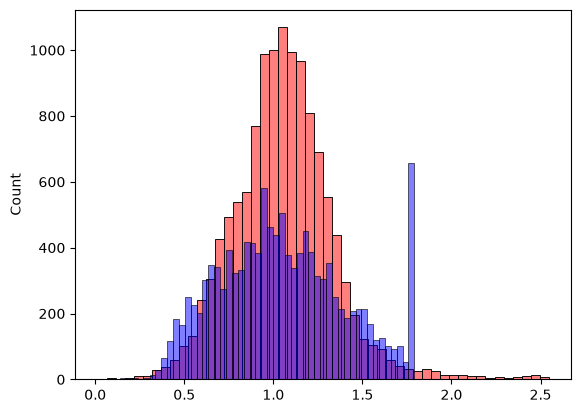

In [139]:
sns.histplot(y_pred, color='red', alpha=0.5, bins=50)
sns.histplot(y_train, color='blue', alpha=0.5, bins=50)

In [140]:
X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
rmse(y_val, y_pred)

np.float64(0.21563205172956362)

<Axes: ylabel='Count'>

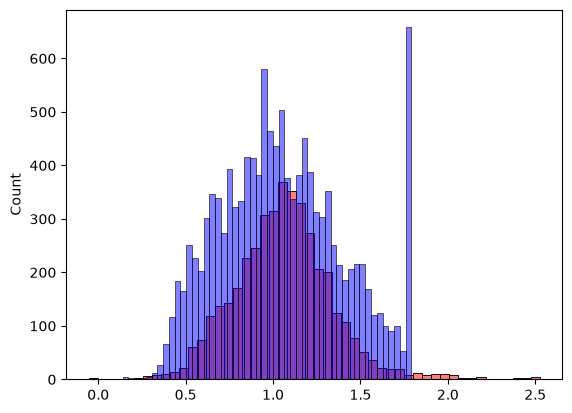

In [141]:
sns.histplot(y_pred, color='red', alpha=0.5, bins=50)
sns.histplot(y_train, color='blue', alpha=0.5, bins=50)

In [142]:
for r in [0.0, 0.00001, 0.0001, 0.001, 0.1, 1, 10]:
    X_train = prepare_X(df_train)
    w0, w = train_linear_regression(X_train, y_train, r=r)

    X_val = prepare_X(df_val)
    y_pred = w0 + X_val.dot(w)
    score = rmse(y_val, y_pred)

    print(r, w0, score)

0.0 -13.506374521433669 0.21563205172956362
1e-05 -13.5061846082166 0.21563207494892975
0.0001 -13.504475630420337 0.21563228432848064
0.001 -13.487409611295377 0.21563441815492917
0.1 -11.84136692232511 0.21620643341405563
1 -5.613940207773671 0.22475164174704884
10 -0.8982393861475685 0.23733256359654661


In [143]:
df_full_train = pd.concat([df_train, df_val])
df_full_train = df_full_train.reset_index(drop=True)
y_full_train = np.concatenate([y_train, y_val])

In [144]:
X_full_train = prepare_X(df_full_train)
w0, w = train_linear_regression(X_full_train, y_full_train, r=0.001)

In [145]:
X_test = prepare_X(df_test)
y_pred = w0 + X_test.dot(w)
score = rmse(y_test, y_pred)
score

np.float64(0.22204249698625667)

In [154]:
test = 67
house = df_test.iloc[test].to_dict()
house

{'medinc': 3.7796,
 'houseage': 21.0,
 'averooms': 5.256997455470738,
 'avebedrms': 1.037319762510602,
 'population': 2827.0,
 'aveoccup': 2.3977947413061917,
 'latitude': 38.67,
 'longitude': -121.16}

In [155]:
df_small = pd.DataFrame([house])
X_small = prepare_X(df_small)

In [156]:
y_pred = w0 + X_small.dot(w)
y_pred = y_pred[0]
np.expm1(y_pred)

np.float64(1.2167625001273321)

In [157]:
np.expm1(y_test[test])

np.float64(1.5900000000000003)